# **Dataset Livros**

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# -------- 1. CATÁLOGO DE LIVROS (50 títulos) --------
# Organizados em 10 gêneros x 5 livros cada (facilita padrões latentes)
livros_por_genero = {
    'Fantasia': [
        'O Hobbit', 'O Senhor dos Anéis', 'As Crônicas de Nárnia',
        'A Roda do Tempo', 'O Nome do Vento'
    ],
    'Ficção Científica': [
        'Duna', 'Neuromancer', 'Fundação', 'O Problema dos Três Corpos',
        'Andróides Sonham com Ovelhas Elétricas?'
    ],
    'Romance': [
        'Orgulho e Preconceito', 'Jane Eyre', 'O Morro dos Ventos Uivantes',
        'Razão e Sensibilidade', 'A Culpa é das Estrelas'
    ],
    'Mistério': [
        'O Assassinato no Expresso do Oriente', 'O Nome da Rosa',
        'Garota Exemplar', 'O Silêncio dos Inocentes', 'A Menina que Roubava Livros'
    ],
    'Terror': [
        'O Iluminado', 'It: A Coisa', 'Drácula', 'Frankenstein', 'O Exorcista'
    ],
    'Distopia': [
        '1984', 'Admirável Mundo Novo', 'Fahrenheit 451', 'Laranja Mecânica',
        'O Conto da Aia'
    ],
    'Não-Ficção': [
        'Sapiens', 'Homo Deus', 'Uma Breve História do Tempo',
        'O Poder do Hábito', 'Rápido e Devagar'
    ],
    'Clássicos': [
        'Dom Casmurro', 'Crime e Castigo', 'Guerra e Paz',
        'Cem Anos de Solidão', 'Grande Sertão: Veredas'
    ],
    'Aventura': [
        'Moby Dick', 'A Ilha do Tesouro', 'Robinson Crusoé',
        'Vinte Mil Léguas Submarinas', 'O Conde de Monte Cristo'
    ],
    'Autoajuda': [
        'O Poder da Ação', 'Mindset', 'Os 7 Hábitos das Pessoas Altamente Eficazes',
        'Como Fazer Amigos e Influenciar Pessoas', 'O Milagre da Manhã'
    ]
}

# Lista plana de títulos e mapa título -> gênero (índice 0-9)
livros = [titulo for genero in livros_por_genero.values() for titulo in genero]
genero_por_livro = np.array(
    [idx for idx, genero in enumerate(livros_por_genero) for _ in livros_por_genero[genero]]
)

n_livros = len(livros)          # 50
n_usuarios = 1000
n_generos = len(livros_por_genero)  # 10

# -------- 2. PERFIS LATENTES DOS USUÁRIOS --------
# Cada usuário tem um vetor de preferências (Dirichlet) sobre os 10 gêneros
preferencias = np.random.dirichlet(alpha=[1.0]*n_generos, size=n_usuarios)

# -------- 3. GERAR RATINGS (matriz densa 1000 × 50) --------
ratings_denso = np.zeros((n_usuarios, n_livros))
for u in range(n_usuarios):
    for l in range(n_livros):
        base = preferencias[u, genero_por_livro[l]] * n_generos  # ~0 a 10
        ruido = np.random.normal(0, 0.6)
        ratings_denso[u, l] = np.clip(round(base + ruido, 1), 1, 5)

# -------- 4. APLICAR ESPARSIDADE DE 60% --------
mascara = np.random.rand(n_usuarios, n_livros) > 0.60  # 60% NaN
ratings_esparso = np.where(mascara, ratings_denso, np.nan)

print(f"Shape da matriz: {ratings_esparso.shape}")
print(f"Células totais: {ratings_esparso.size:,}")
print(f"Ratings observados: {np.sum(~np.isnan(ratings_esparso)):,}")
print(f"Ratings ausentes (NaN): {np.sum(np.isnan(ratings_esparso)):,}")
print(f"Esparsidade: {100*np.isnan(ratings_esparso).mean():.2f}%")

# -------- 5. CONVERTER PARA FORMATO LONG (tidy) --------
# Cada linha = (USER_ID, TITLE, RATING)
registros = []
for u_idx in range(n_usuarios):
    for l_idx in range(n_livros):
        rating = ratings_esparso[u_idx, l_idx]
        if not np.isnan(rating):
            registros.append({
                'USER_ID': u_idx + 1,          # IDs numéricos 1..1000
                'TITLE': livros[l_idx],
                'RATING': float(rating)
            })

df_ratings = pd.DataFrame(registros)





Shape da matriz: (1000, 50)
Células totais: 50,000
Ratings observados: 19,945
Ratings ausentes (NaN): 30,055
Esparsidade: 60.11%


In [4]:
print("\n===== DATAFRAME DE RATINGS =====")
print(df_ratings.head(10))
print(f"\nShape: {df_ratings.shape}")
print(f"Nº de usuários únicos: {df_ratings['USER_ID'].nunique()}")
print(f"Nº de livros únicos: {df_ratings['TITLE'].nunique()}")
print(f"Ratings por usuário (média): {df_ratings.groupby('USER_ID').size().mean():.1f}")
print(f"Ratings por livro  (média): {df_ratings.groupby('TITLE').size().mean():.1f}")
print(f"\nEstatísticas dos ratings:\n{df_ratings['RATING'].describe()}")


===== DATAFRAME DE RATINGS =====
   USER_ID                        TITLE  RATING
0        1                     O Hobbit     1.0
1        1           O Senhor dos Anéis     1.0
2        1        As Crônicas de Nárnia     1.0
3        1                     Fundação     2.8
4        1                    Jane Eyre     1.6
5        1  O Morro dos Ventos Uivantes     1.2
6        1        Razão e Sensibilidade     1.6
7        1       A Culpa é das Estrelas     1.1
8        1               O Nome da Rosa     1.0
9        1  A Menina que Roubava Livros     1.2

Shape: (19945, 3)
Nº de usuários únicos: 1000
Nº de livros únicos: 50
Ratings por usuário (média): 19.9
Ratings por livro  (média): 398.9

Estatísticas dos ratings:
count    19945.000000
mean         1.422923
std          0.733975
min          1.000000
25%          1.000000
50%          1.000000
75%          1.600000
max          5.000000
Name: RATING, dtype: float64



Matriz pivot shape: (1000, 50)
Esparsidade do pivot: 60.11%


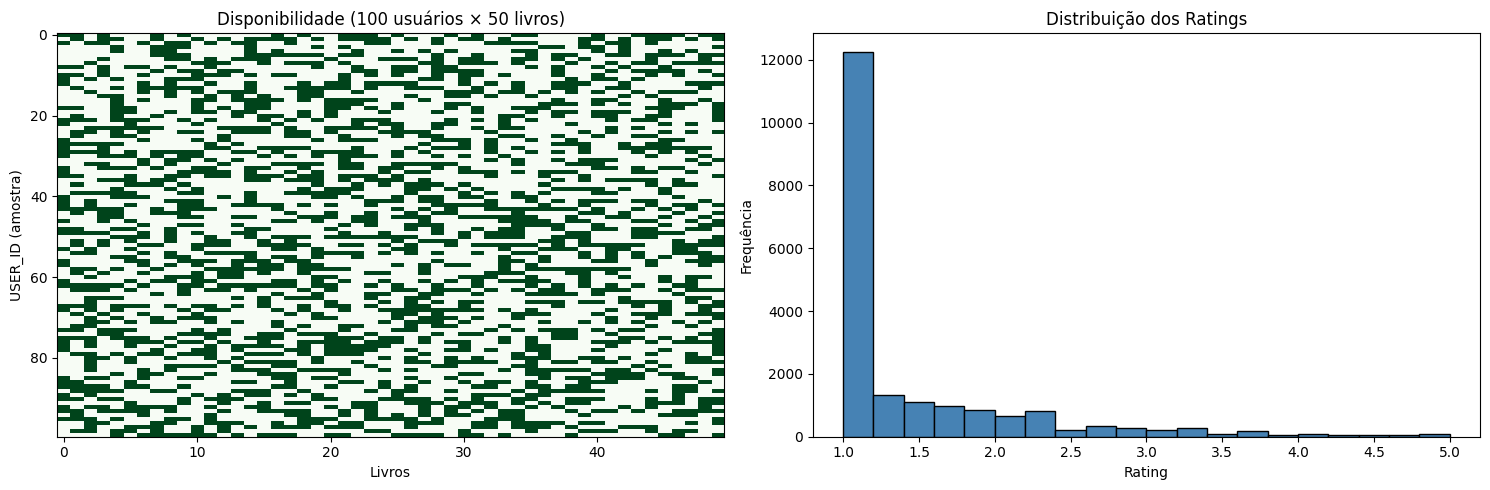

In [6]:
df_pivot = df_ratings.pivot(index='USER_ID', columns='TITLE', values='RATING')
print(f"\nMatriz pivot shape: {df_pivot.shape}")
print(f"Esparsidade do pivot: {100*df_pivot.isna().mean().mean():.2f}%")

# --------  VISUALIZAÇÃO --------
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Heatmap de disponibilidade (amostra de 100 usuários)
axes[0].imshow(df_pivot.iloc[:100].notna().values, aspect='auto', cmap='Greens')
axes[0].set_title('Disponibilidade (100 usuários × 50 livros)')
axes[0].set_xlabel('Livros')
axes[0].set_ylabel('USER_ID (amostra)')

# Distribuição dos ratings
axes[1].hist(df_ratings['RATING'], bins=20, color='steelblue', edgecolor='black')
axes[1].set_title('Distribuição dos Ratings')
axes[1].set_xlabel('Rating')
axes[1].set_ylabel('Frequência')

plt.tight_layout()
plt.show()

**Atividade -  Crie um sistema de recomendação para os usuários baseado no algoritmo SVD**